<a href="https://colab.research.google.com/github/zeeshansafdar752/Research_Paper/blob/main/ResearchPaper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Import Libraries

2 Load Dataset

3 Check Dataset

4 Clean Data

5 Define Target

6 Train / Validation / Test Split

7 Preprocessing

8 Baseline Model (Random Forest)

9 Choose Algorithm

10 Define Loss, Activation Function aur Optimizer

11 Training Loop (validation, early stopping)

12 Check Training Output (learning curves)

13 Model Evaluation (test set par, confusion matrix)

14 Error Analysis

15 Repeat with Multiple Seeds

16 Save Model


**# Import Libraries**

In [50]:
# Import Libraries
import os, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import zipfile
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import glob
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)
from sklearn.preprocessing import OneHotEncoder
import os
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import shutil
import time, copy
from xgboost import XGBClassifier
import itertools

**Select Device CPU or GPU**

In [11]:
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


**# Drive mount**

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import glob
hits = glob.glob("/content/drive/MyDrive/Colab Notebooks/xfl/train_test_network.csv", recursive=True)
print("found:", hits)
DATA_PATH = hits[0]
df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)

found: ['/content/drive/MyDrive/Colab Notebooks/xfl/train_test_network.csv']
(211043, 44)


In [17]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


**Load Dataset**

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes        

In [19]:
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

# The loaded CSV file only contains traffic features.
# Since we loaded 'benign_traffic.csv', we can define 'label' as 0 (benign) and 'type' as 'benign'.
if "label" not in df.columns:
    df["label"] = 0
if "type" not in df.columns:
    df["type"] = "benign"

print("\n--- Label Distributions ---")
print(df["type"].value_counts())
print(df["label"].value_counts())

missing values: 0
duplicate rows: 20569

--- Label Distributions ---
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
scanning      20000
ransomware    20000
xss           20000
mitm           1043
Name: count, dtype: int64
label
1    161043
0     50000
Name: count, dtype: int64


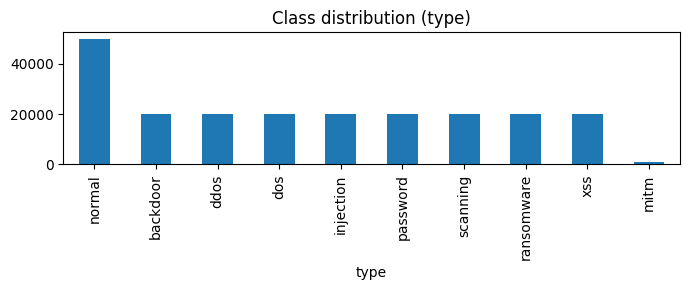

In [20]:
df["type"].value_counts().plot(kind="bar", figsize=(7, 3), title="Class distribution (type)")
plt.tight_layout(); plt.show()

**Cleen Data**

In [21]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.replace("-", np.nan).replace([np.inf, -np.inf], np.nan)
# columns that only looked like text because of "-" become numbers again
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]) and c != "type":
        converted = pd.to_numeric(df[c], errors="coerce")
        if converted.notna().sum() >= 0.9 * df[c].notna().sum():
            df[c] = converted

In [22]:
id_cols = ["ts", "src_ip", "dst_ip", "src_port", "dst_port"]
df = df.drop(columns=[c for c in id_cols if c in df.columns])

# text columns with too many different values (dns_query, http_uri, ...) are not useful as numbers
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 50 and c != "type"]
print("dropping text columns:", text_cols)
df = df.drop(columns=text_cols)
print(df.shape)

dropping text columns: ['dns_query', 'http_uri']
(190474, 38)


**Define Targets**

In [23]:
y_text = df["type"]
X = df.drop(columns=["type", "label"], errors="ignore")

le = LabelEncoder()
y = le.fit_transform(y_text)
class_names = list(le.classes_)
print(class_names)

cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print("categorical:", cat_cols)
print("numeric:", len(num_cols))

['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']
categorical: ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_method', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']
numeric: 17


**Split data into==> Test-->Train and validaction**

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, stratify=y_train, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

133331 19048 38095


**Data Preprocessing**

In [25]:
def transform(part, med, log_cols, scaler, enc):
    part = part.copy()
    part[num_cols] = part[num_cols].fillna(med)
    part[log_cols] = np.log1p(part[log_cols].clip(lower=0))
    out = scaler.transform(part[num_cols])
    if enc is not None:
        out = np.hstack([out, enc.transform(part[cat_cols].fillna("missing").astype(str))])
    return np.clip(out.astype("float32"), -10, 10)

def preprocess(X_train, X_val, X_test):
    med = X_train[num_cols].median()
    # decided on the train set only: never negative and large values
    log_cols = [c for c in num_cols if X_train[c].min() >= 0 and X_train[c].max() > 100]
    t = X_train.copy()
    t[num_cols] = t[num_cols].fillna(med)
    t[log_cols] = np.log1p(t[log_cols].clip(lower=0))
    scaler = StandardScaler().fit(t[num_cols])
    enc = None
    if cat_cols:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        enc.fit(X_train[cat_cols].fillna("missing").astype(str))
    arrays = [transform(p, med, log_cols, scaler, enc) for p in (X_train, X_val, X_test)]
    assert all(not np.isnan(a).any() for a in arrays), "NaN left after preprocessing"
    return arrays[0], arrays[1], arrays[2], enc, scaler, med, log_cols

Xtr, Xva, Xte, enc, scaler, med, log_cols = preprocess(X_train, X_val, X_test)
print(Xtr.shape, len(log_cols), "log columns")

(133331, 135) 13 log columns


In [26]:
# class weights from the train set (the classes are not perfectly balanced)
counts = np.bincount(y_train, minlength=len(class_names))
class_weights = torch.tensor(counts.sum() / (len(class_names) * np.maximum(counts, 1)), dtype=torch.float32)
print(class_weights)

tensor([ 1.0179,  0.9527,  1.0029,  0.9541, 18.2896,  0.4531,  0.9590,  1.2927,
         0.9524,  1.2583])


**BaseLine Model (Random Forest)**

In [27]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
rf.fit(Xtr, y_train)
rf_pred = rf.predict(Xva)
print("RF validation macro-F1:", round(f1_score(y_val, rf_pred, average="macro"), 4))

RF validation macro-F1: 0.9513


**DataLoaders**

In [28]:
BATCH = 256
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = make_loader(Xtr, y_train, True)
val_loader = make_loader(Xva, y_val, False)
test_loader = make_loader(Xte, y_test, False)

**CNN-LSTM**

In [29]:
class CNNLSTM(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.MaxPool1d(2))
        self.lstm = nn.LSTM(32, 64, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.conv(x.unsqueeze(1))        # (batch, 32, n_features/2)
        x = x.transpose(1, 2)                # (batch, steps, 32)
        out, _ = self.lstm(x)                # LSTM output at every step
        z = torch.cat([out.mean(1), out.max(1).values], dim=1)   # average and max over all steps
        return self.fc(self.drop(z))

set_seed(SEED)
model = CNNLSTM(Xtr.shape[1], len(class_names)).to(device)
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

CNNLSTM(
  (conv): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(32, 64, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
parameters: 29738


**Define Loss, Activation Funcation and Optimizer**

In [52]:
loss_fn = nn.CrossEntropyLoss()

**Traning Loop**

In [31]:
def predict(model, loader):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for xb, _ in loader:
            out = model(xb.to(device))
            probs.append(torch.softmax(out, 1).cpu().numpy())
            preds.append(out.argmax(1).cpu().numpy())
    return np.concatenate(preds), np.concatenate(probs)

In [53]:
def train_model(model, train_loader, val_loader, y_val, epochs=40, patience=6, save_path="best_model.pt", verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    history = {"train_loss": [], "val_f1": []}
    best_f1, bad_epochs = 0, 0
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # gradient clipping
            opt.step()
            opt.step()
            total += loss.item() * len(xb)
        train_loss = total / len(train_loader.dataset)
        val_pred, _ = predict(model, val_loader)
        val_f1 = f1_score(y_val, val_pred, average="macro")
        sched.step(val_f1)
        history["train_loss"].append(train_loss); history["val_f1"].append(val_f1)
        if verbose:
            print(f"epoch {epoch+1:2d}  train loss {train_loss:.4f}  val macro-F1 {val_f1:.4f}")
        if val_f1 > best_f1:                 # early stopping: keep the best model
            best_f1, bad_epochs = val_f1, 0
            torch.save(model.state_dict(), save_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("early stopping at epoch", epoch + 1)
                break
    model.load_state_dict(torch.load(save_path, map_location=device))
    return history

In [54]:
history = train_model(model, train_loader, val_loader, y_val)

epoch  1  train loss 0.2191  val macro-F1 0.9085
epoch  2  train loss 0.1805  val macro-F1 0.9138
epoch  3  train loss 0.1585  val macro-F1 0.9243
epoch  4  train loss 0.1509  val macro-F1 0.9214
epoch  5  train loss 0.1345  val macro-F1 0.9267
epoch  6  train loss 0.1304  val macro-F1 0.9249
epoch  7  train loss 0.1261  val macro-F1 0.9272
epoch  8  train loss 0.1286  val macro-F1 0.9316
epoch  9  train loss 0.1170  val macro-F1 0.9290
epoch 10  train loss 0.1207  val macro-F1 0.9348
epoch 11  train loss 0.1080  val macro-F1 0.9350
epoch 12  train loss 0.1094  val macro-F1 0.9273
epoch 13  train loss 0.1060  val macro-F1 0.9365
epoch 14  train loss 0.1064  val macro-F1 0.9361
epoch 15  train loss 0.1045  val macro-F1 0.9379
epoch 16  train loss 0.0978  val macro-F1 0.9368
epoch 17  train loss 0.1026  val macro-F1 0.9358
epoch 18  train loss 0.1012  val macro-F1 0.9392
epoch 19  train loss 0.0950  val macro-F1 0.9297
epoch 20  train loss 0.0945  val macro-F1 0.9354
epoch 21  train loss

Show Result in Graphas

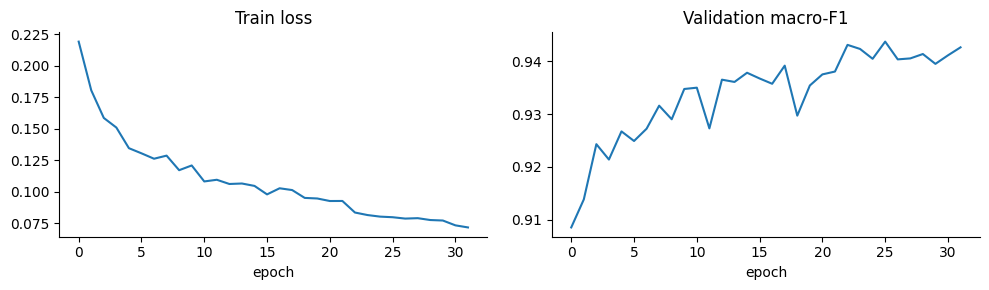

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history["val_f1"]); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Model Evaluation**

In [56]:
test_pred, test_prob = predict(model, test_loader)
acc = accuracy_score(y_test, test_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, test_pred, average="macro", zero_division=0)
print(f"accuracy {acc:.4f}  macro-P {p:.4f}  macro-R {r:.4f}  macro-F1 {f1:.4f}")
try:
    print("macro ROC-AUC:", round(roc_auc_score(y_test, test_prob, multi_class="ovr", average="macro"), 4))
except ValueError as e:
    print("ROC-AUC not computed:", e)
print(classification_report(y_test, test_pred, target_names=class_names, zero_division=0))

accuracy 0.9726  macro-P 0.9340  macro-R 0.9561  macro-F1 0.9432
macro ROC-AUC: 0.9988
              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      3742
        ddos       0.98      0.96      0.97      3999
         dos       0.99      0.97      0.98      3799
   injection       0.98      0.94      0.96      3993
        mitm       0.61      0.83      0.70       208
      normal       0.99      0.99      0.99      8408
    password       1.00      0.98      0.99      3972
  ransomware       0.91      0.97      0.94      2947
    scanning       0.98      1.00      0.99      4000
         xss       0.90      0.93      0.91      3027

    accuracy                           0.97     38095
   macro avg       0.93      0.96      0.94     38095
weighted avg       0.97      0.97      0.97     38095



**Classification report**

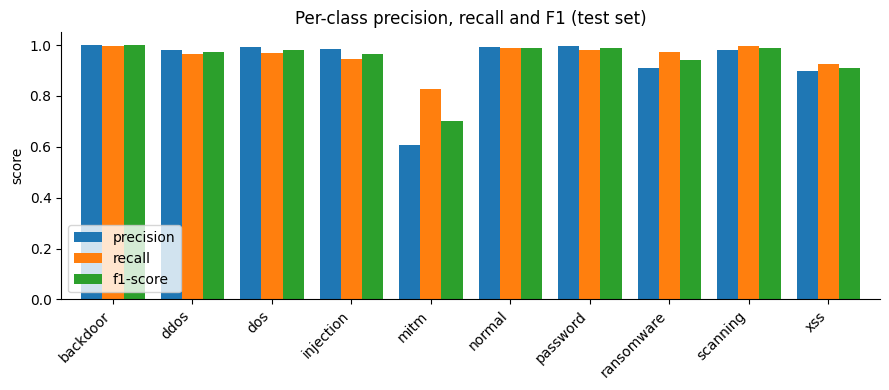

In [57]:
report = classification_report(y_test, test_pred, target_names=class_names, zero_division=0, output_dict=True)
rep = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score"]]

rep.plot(kind="bar", figsize=(9, 4), width=0.8)
plt.ylim(0, 1.05)
plt.title("Per-class precision, recall and F1 (test set)")
plt.ylabel("score")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower left")
plt.tight_layout(); plt.show()

**confusion_matrix**

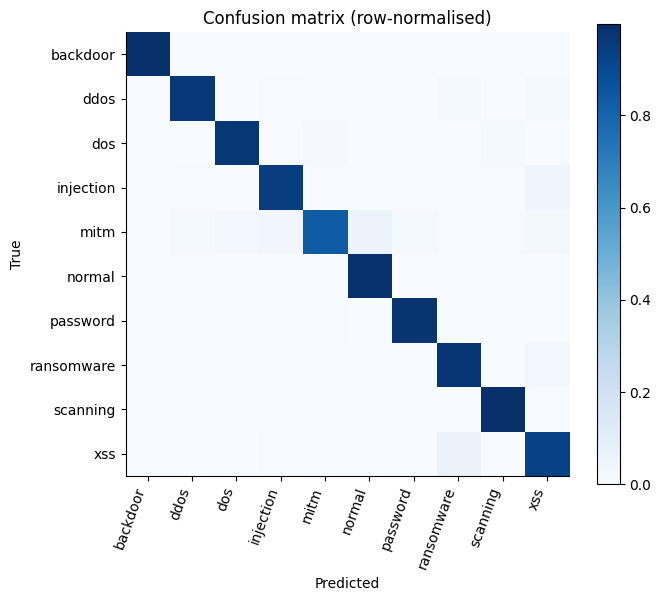

Random Forest test macro-F1: 0.9523
CNN-LSTM test macro-F1:      0.9432


In [58]:
cm = confusion_matrix(y_test, test_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(7, 6))
plt.imshow(cm_norm, cmap="Blues")
plt.xticks(range(len(class_names)), class_names, rotation=70, ha="right")
plt.yticks(range(len(class_names)), class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (row-normalised)")
plt.colorbar(); plt.tight_layout(); plt.show()

# baseline on the same test set
rf_test = rf.predict(Xte)
print("Random Forest test macro-F1:", round(f1_score(y_test, rf_test, average="macro"), 4))
print("CNN-LSTM test macro-F1:     ", round(f1, 4))

**Error Analysis**

In [59]:
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)
for _ in range(5):
    i, j = np.unravel_index(mistakes.argmax(), mistakes.shape)
    print(f"{class_names[i]} predicted as {class_names[j]}: {mistakes[i, j]} flows")
    mistakes[i, j] = 0

xss predicted as ransomware: 195 flows
injection predicted as xss: 160 flows
ransomware predicted as xss: 82 flows
dos predicted as scanning: 58 flows
ddos predicted as xss: 53 flows


**Repeat with multiplat seed**

In [60]:
def run_once(seed, epochs=25):
    set_seed(seed)
    Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    Xa, Xv, ya, yv = train_test_split(Xa, ya, test_size=0.125, stratify=ya, random_state=seed)
    a, b, c, _, _, _, _ = preprocess(Xa, Xv, Xt)
    m = CNNLSTM(a.shape[1], len(class_names)).to(device)
    train_model(m, make_loader(a, ya, True), make_loader(b, yv, False), yv, epochs=epochs,
                save_path=f"tmp_seed{seed}.pt", verbose=False)
    pred, _ = predict(m, make_loader(c, yt, False))
    forest = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed).fit(a, ya)
    return f1_score(yt, pred, average="macro"), f1_score(yt, forest.predict(c), average="macro")

results = [run_once(s) for s in [1, 2, 3, 4, 5]]
res = pd.DataFrame(results, columns=["CNN-LSTM", "RandomForest"])
print(res.round(4))
print("mean:\n", res.mean().round(4), "\nstd:\n", res.std().round(4))

   CNN-LSTM  RandomForest
0    0.9466        0.9495
1    0.9397        0.9533
2    0.9410        0.9500
3    0.9386        0.9545
4    0.9362        0.9502
mean:
 CNN-LSTM        0.9404
RandomForest    0.9515
dtype: float64 
std:
 CNN-LSTM        0.0039
RandomForest    0.0022
dtype: float64


**Paper-ready figures aur tables**

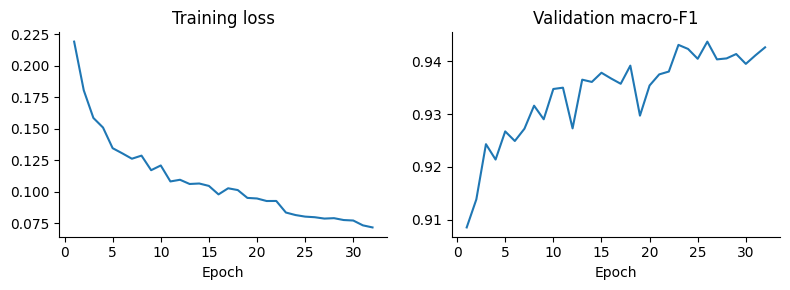

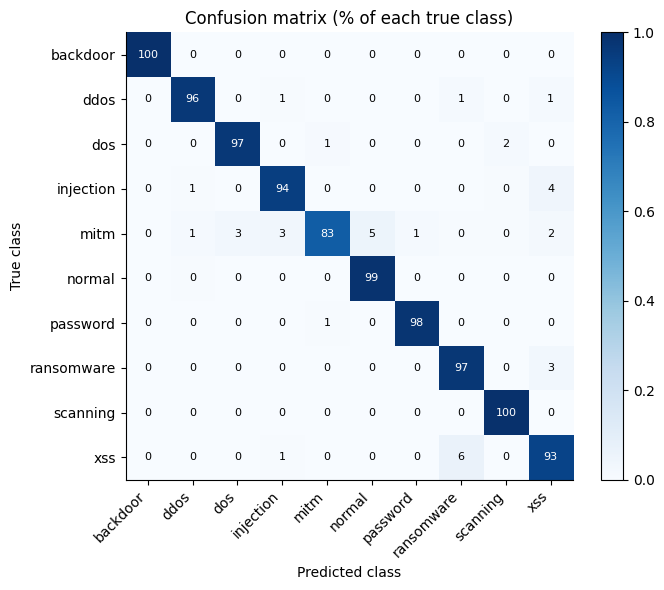

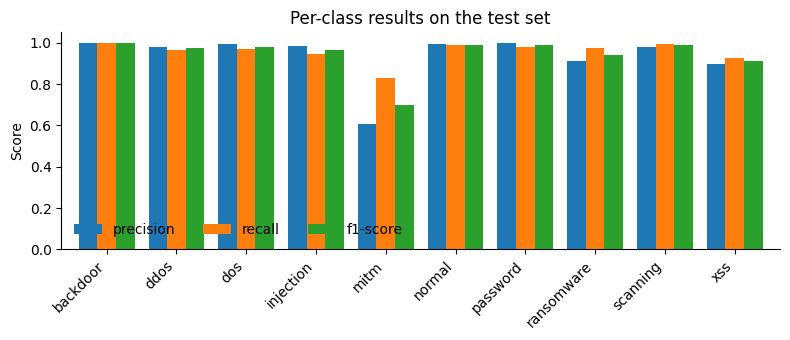

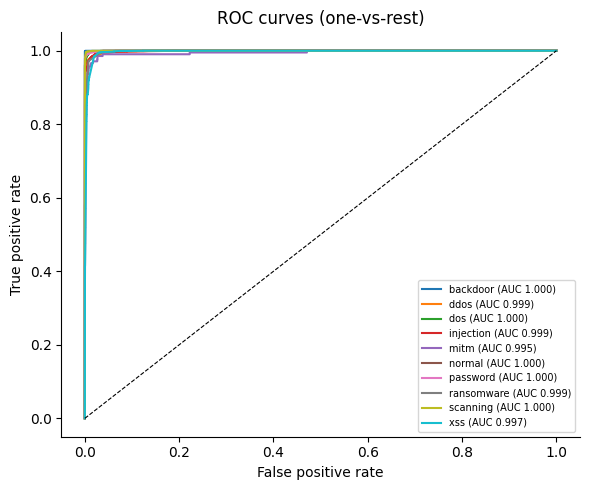

        Model  Accuracy  Macro-Precision  Macro-Recall  Macro-F1
Random Forest    0.9770           0.9501        0.9548    0.9523
     CNN-LSTM    0.9726           0.9340        0.9561    0.9432

            precision  recall  f1-score
backdoor        0.999   0.998     0.999
ddos            0.979   0.965     0.972
dos             0.992   0.967     0.979
injection       0.984   0.943     0.963
mitm            0.608   0.827     0.701
normal          0.993   0.988     0.990
password        0.996   0.980     0.988
ransomware      0.910   0.972     0.940
scanning        0.981   0.995     0.988
xss             0.898   0.926     0.911

saved in paper_figures/: ['fig1_learning_curves.png', 'fig2_confusion_matrix.png', 'fig3_per_class_metrics.png', 'fig4_roc_curves.png', 'table1_model_comparison.csv', 'table2_per_class.csv', 'table3_model_cost.csv', 'table4_baselines.csv']


In [61]:
os.makedirs("paper_figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# 1. learning curves
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].plot(range(1, len(history["train_loss"]) + 1), history["train_loss"]); ax[0].set_title("Training loss")
ax[1].plot(range(1, len(history["val_f1"]) + 1), history["val_f1"]); ax[1].set_title("Validation macro-F1")
for a in ax: a.set_xlabel("Epoch")
plt.tight_layout(); plt.savefig("paper_figures/fig1_learning_curves.png", dpi=300); plt.show()

# 2. confusion matrix with percentages
cm = confusion_matrix(y_test, test_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j, i, f"{cm_norm[i, j]*100:.0f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Confusion matrix (% of each true class)")
fig.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
plt.savefig("paper_figures/fig2_confusion_matrix.png", dpi=300); plt.show()

# 3. per-class precision / recall / F1
report = classification_report(y_test, test_pred, target_names=class_names, zero_division=0, output_dict=True)
rep = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score"]]
rep.plot(kind="bar", figsize=(8, 3.5), width=0.8)
plt.ylim(0, 1.05); plt.ylabel("Score"); plt.title("Per-class results on the test set")
plt.xticks(rotation=45, ha="right"); plt.legend(loc="lower left", ncol=3, frameon=False)
plt.tight_layout(); plt.savefig("paper_figures/fig3_per_class_metrics.png", dpi=300); plt.show()

# 4. ROC curves (one class against the rest)
Y = label_binarize(y_test, classes=range(len(class_names)))
plt.figure(figsize=(6, 5))
for k, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(Y[:, k], test_prob[:, k])
    plt.plot(fpr, tpr, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (one-vs-rest)")
plt.legend(fontsize=7, loc="lower right"); plt.tight_layout()
plt.savefig("paper_figures/fig4_roc_curves.png", dpi=300); plt.show()

# 5. tables for the paper
rf_test = rf.predict(Xte)
def row(name, pred):
    p_, r_, f_, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return [name, accuracy_score(y_test, pred), p_, r_, f_]
comp = pd.DataFrame([row("Random Forest", rf_test), row("CNN-LSTM", test_pred)],
                    columns=["Model", "Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]).round(4)
comp.to_csv("paper_figures/table1_model_comparison.csv", index=False)
rep.round(4).to_csv("paper_figures/table2_per_class.csv")
print(comp.to_string(index=False)); print(); print(rep.round(3))
print("\nsaved in paper_figures/:", sorted(os.listdir("paper_figures")))

**save model**

In [62]:
os.makedirs("saved", exist_ok=True)
torch.save(model.state_dict(), "saved/cnn_lstm.pt")
joblib.dump(scaler, "saved/scaler.pkl")
joblib.dump(enc, "saved/onehot_encoder.pkl")
joblib.dump(med, "saved/train_medians.pkl")
json.dump({"class_names": class_names, "cat_cols": cat_cols, "num_cols": num_cols, "log_cols": log_cols,
           "n_features": int(Xtr.shape[1]),
           "test_macro_f1": float(f1), "test_accuracy": float(acc)}, open("saved/info.json", "w"), indent=1)
print(os.listdir("saved"))

['scaler.pkl', 'info.json', 'onehot_encoder.pkl', 'cnn_lstm.pt', 'train_medians.pkl']


Inference Demo

In [63]:
info = json.load(open("saved/info.json"))
scaler2 = joblib.load("saved/scaler.pkl")
enc2 = joblib.load("saved/onehot_encoder.pkl")
med2 = joblib.load("saved/train_medians.pkl")

sample = transform(X_test.iloc[:5], med2, info["log_cols"], scaler2, enc2)

model2 = CNNLSTM(info["n_features"], len(info["class_names"])).to(device)
model2.load_state_dict(torch.load("saved/cnn_lstm.pt", map_location=device))
model2.eval()
with torch.no_grad():
    out = model2(torch.from_numpy(sample).to(device)).argmax(1).cpu().numpy()
for pred, true in zip(out, y_test[:5]):
    print("predicted:", info["class_names"][pred], "| actual:", info["class_names"][true])

predicted: password | actual: password
predicted: normal | actual: normal
predicted: password | actual: password
predicted: normal | actual: normal
predicted: normal | actual: normal


**Zip Paper Figures**

In [67]:
shutil.make_archive("paper_figures", "zip", "paper_figures")

'/content/paper_figures.zip'

**Model Cost (parameters, size, latency)**

In [65]:
def model_cost(m, X_sample, train_loader):
    out = {}
    out["parameters"] = sum(p.numel() for p in m.parameters())
    torch.save(m.state_dict(), "size_check.pt")
    out["model_size_KB"] = round(os.path.getsize("size_check.pt") / 1024, 1)
    os.remove("size_check.pt")

    m.eval()
    one = torch.from_numpy(X_sample[:1]).to(device)
    with torch.no_grad():
        for _ in range(20): m(one)                       # warm up
        if device.type == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(200): m(one)
        if device.type == "cuda": torch.cuda.synchronize()
    out["latency_ms_per_flow (batch 1)"] = round((time.time() - t) / 200 * 1000, 3)

    big = torch.from_numpy(X_sample[:2048]).to(device)
    with torch.no_grad():
        if device.type == "cuda": torch.cuda.synchronize()
        t = time.time(); m(big)
        if device.type == "cuda": torch.cuda.synchronize()
    out["throughput_flows_per_sec (batch 2048)"] = int(len(big) / (time.time() - t))

    tmp = copy.deepcopy(m).train()                       # one training epoch on a copy, the real model is not touched
    opt = torch.optim.Adam(tmp.parameters(), lr=1e-3)
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss_fn(tmp(xb), yb).backward(); opt.step()
    if device.type == "cuda": torch.cuda.synchronize()
    out["seconds_per_training_epoch"] = round(time.time() - t, 1)
    out["device"] = str(device)
    return out

cost = model_cost(model, Xte, train_loader)
for k, v in cost.items():
    print(f"{k}: {v}")
os.makedirs("paper_figures", exist_ok=True)
pd.Series(cost).to_csv("paper_figures/table3_model_cost.csv", header=["value"])

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1164: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  result = _VF.lstm(


parameters: 29738
model_size_KB: 123.1
latency_ms_per_flow (batch 1): 0.745
throughput_flows_per_sec (batch 2048): 150724
seconds_per_training_epoch: 2.8
device: cuda


**Baselines (XGBoost, MLP, CNN, LSTM)**

In [66]:
n_feat, n_cls = Xtr.shape[1], len(class_names)

class CNNOnly(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU())
        self.fc = nn.Linear(64, n_classes)
    def forward(self, x):
        z = self.conv(x.unsqueeze(1))                       # (batch, 32, n_features)
        return self.fc(torch.cat([z.mean(2), z.max(2).values], dim=1))

class LSTMOnly(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.lstm = nn.LSTM(1, 64, batch_first=True)
        self.fc = nn.Linear(128, n_classes)
    def forward(self, x):
        out, _ = self.lstm(x.unsqueeze(2))                  # each feature is one step
        return self.fc(torch.cat([out.mean(1), out.max(1).values], dim=1))

def score(pred):
    p_, r_, f_, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return accuracy_score(y_test, pred), p_, r_, f_

rows = []
# classical models
t = time.time()
xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED)
xgb.fit(Xtr, y_train)
rows.append(["XGBoost", *score(xgb.predict(Xte)), None, round(time.time() - t, 1)])
rows.append(["Random Forest", *score(rf.predict(Xte)), None, None])

# neural models, same loaders, same loss, same training loop
for name, M in [("MLP", None), ("CNN only", CNNOnly), ("LSTM only", LSTMOnly), ("CNN-LSTM (ours)", CNNLSTM)]:
    set_seed(SEED)
    if M is None:
        m = nn.Sequential(nn.Linear(n_feat, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, n_cls)).to(device)
    else:
        m = M(n_feat, n_cls).to(device)
    t = time.time()
    train_model(m, train_loader, val_loader, y_val, save_path="baseline_tmp.pt", verbose=False)
    secs = round(time.time() - t, 1)
    pred, _ = predict(m, test_loader)
    rows.append([name, *score(pred), sum(p.numel() for p in m.parameters()), secs])
    print(name, "done")

base = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1", "Parameters", "Train seconds"])
base[["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]] = base[["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]].round(4)
os.makedirs("paper_figures", exist_ok=True)
base.to_csv("paper_figures/table4_baselines.csv", index=False)
print(base.to_string(index=False))

early stopping at epoch 36
MLP done
early stopping at epoch 39
CNN only done
LSTM only done
early stopping at epoch 32
CNN-LSTM (ours) done
          Model  Accuracy  Macro-Precision  Macro-Recall  Macro-F1  Parameters  Train seconds
        XGBoost    0.9794           0.9550        0.9591    0.9569         NaN           73.8
  Random Forest    0.9770           0.9501        0.9548    0.9523         NaN            NaN
            MLP    0.9727           0.9382        0.9513    0.9440     26314.0           84.8
       CNN only    0.9547           0.9138        0.9120    0.9126      4010.0          112.3
      LSTM only    0.9677           0.9276        0.9337    0.9303     18442.0          118.2
CNN-LSTM (ours)    0.9726           0.9368        0.9533    0.9439     29738.0          118.4


**Class weight aur learning rate ka tuning**

In [51]:
def train_cfg(lr, wt, epochs=40, patience=6):
    set_seed(SEED)
    m = CNNLSTM(Xtr.shape[1], len(class_names)).to(device)
    lf = nn.CrossEntropyLoss(weight=wt.to(device))
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    best, bad, best_state = 0, 0, None
    for epoch in range(epochs):
        m.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            lf(m(xb), yb).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)      # gradient clipping
            opt.step()
        vp, _ = predict(m, val_loader)
        f = f1_score(y_val, vp, average="macro")
        sched.step(f)
        if f > best:
            best, bad = f, 0
            best_state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(best_state)
    return m, best

weight_options = {"full": class_weights, "sqrt": class_weights ** 0.5, "none": torch.ones_like(class_weights)}
rows, models = [], {}
mitm_id = class_names.index("mitm")
for (wname, wt), lr in itertools.product(weight_options.items(), [1e-3, 3e-4]):
    t = time.time()
    m, best = train_cfg(lr, wt)
    vp, _ = predict(m, val_loader)
    mitm_f1 = f1_score(y_val, vp, labels=[mitm_id], average=None)[0]
    rows.append([wname, lr, round(best, 4), round(mitm_f1, 4), round(time.time() - t)])
    models[(wname, lr)] = m
    print("done", wname, lr)

tune = pd.DataFrame(rows, columns=["class weight", "lr", "val macro-F1", "val mitm F1", "seconds"])
print(tune.to_string(index=False))
best_row = tune.sort_values("val macro-F1", ascending=False).iloc[0]
print("\nbest on VALIDATION:", best_row["class weight"], best_row["lr"])

# test set is used only once, for the setting chosen on validation
best_model = models[(best_row["class weight"], best_row["lr"])]
tp, tprob = predict(best_model, test_loader)
print("test macro-F1:", round(f1_score(y_test, tp, average="macro"), 4), "| test accuracy:", round(accuracy_score(y_test, tp), 4))
print(classification_report(y_test, tp, target_names=class_names, zero_division=0, digits=3))

done full 0.001
done full 0.0003
done sqrt 0.001
done sqrt 0.0003
done none 0.001
done none 0.0003
class weight     lr  val macro-F1  val mitm F1  seconds
        full 0.0010        0.9333       0.6125      132
        full 0.0003        0.9325       0.6109      134
        sqrt 0.0010        0.9378       0.6421      135
        sqrt 0.0003        0.9342       0.6431      126
        none 0.0010        0.9423       0.6743      136
        none 0.0003        0.9327       0.6214      136

best on VALIDATION: none 0.001
test macro-F1: 0.9432 | test accuracy: 0.9728
              precision    recall  f1-score   support

    backdoor      0.999     0.998     0.999      3742
        ddos      0.985     0.963     0.974      3999
         dos      0.990     0.972     0.981      3799
   injection      0.983     0.944     0.963      3993
        mitm      0.619     0.803     0.699       208
      normal      0.989     0.990     0.990      8408
    password      0.997     0.980     0.988      397

**Federated learning**

In [68]:
def make_clients(y, n_clients, alpha, seed):
    # non-IID split: for every class, a Dirichlet(alpha) draw decides how much each client gets (small alpha = more skew)
    rng = np.random.default_rng(seed)
    while True:
        parts = [[] for _ in range(n_clients)]
        for c in np.unique(y):
            idx = rng.permutation(np.where(y == c)[0])
            share = rng.dirichlet([alpha] * n_clients)
            cuts = (np.cumsum(share) * len(idx)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= 50:        # every client needs some data
            return [np.array(p) for p in parts]

def local_train(global_model, idx, epochs, lr, mu):
    model = copy.deepcopy(global_model).to(device)
    model.train()
    start = [p.detach().clone() for p in global_model.parameters()]
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(Xtr[idx], y_train[idx], True)
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            if mu > 0:                                   # FedProx: stay close to the global model
                loss = loss + 0.5 * mu * sum(((p - s) ** 2).sum() for p, s in zip(model.parameters(), start))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    return model.state_dict()

def average(states, sizes):
    total = sum(sizes)
    new = {}
    for k in states[0]:
        if states[0][k].is_floating_point():
            new[k] = sum(s[k] * (n / total) for s, n in zip(states, sizes))
        else:
            new[k] = states[0][k]
    return new

def federated_train(mu=0.0, alpha=0.5, n_clients=5, rounds=30, local_epochs=2, lr=1e-3, seed=SEED, patience=8):
    set_seed(seed)
    clients = make_clients(y_train, n_clients, alpha, seed)
    gmodel = CNNLSTM(Xtr.shape[1], len(class_names)).to(device)
    n_params = sum(p.numel() for p in gmodel.parameters())
    best, bad, best_state, hist = 0, 0, None, []
    t = time.time()
    for r in range(rounds):
        states = [local_train(gmodel, idx, local_epochs, lr, mu) for idx in clients]
        gmodel.load_state_dict(average(states, [len(i) for i in clients]))
        vp, _ = predict(gmodel, val_loader)
        f = f1_score(y_val, vp, average="macro")
        hist.append(f)
        if f > best:
            best, bad, best_state = f, 0, copy.deepcopy(gmodel.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    gmodel.load_state_dict(best_state)
    comm_mb = len(hist) * n_clients * n_params * 4 * 2 / 1e6     # model goes down and up every round, float32
    return gmodel, hist, comm_mb, time.time() - t, clients

rows = []
for alpha in [0.5, 0.1]:
    for name, mu in [("FedAvg", 0.0), ("FedProx", 0.01)]:
        g, hist, mb, secs, clients = federated_train(mu=mu, alpha=alpha)
        tp, _ = predict(g, test_loader)
        rows.append([name, alpha, round(accuracy_score(y_test, tp), 4),
                     round(f1_score(y_test, tp, average="macro"), 4), len(hist), round(mb, 1), round(secs)])
        print("done", name, "alpha", alpha)
fed = pd.DataFrame(rows, columns=["Method", "Dirichlet alpha", "Test accuracy", "Test macro-F1", "Rounds", "Comm MB", "Seconds"])
print(fed.to_string(index=False))
print("\ncentralised CNN-LSTM test macro-F1 (Step 13):", round(f1, 4))
os.makedirs("paper_figures", exist_ok=True)
fed.to_csv("paper_figures/table5_federated.csv", index=False)
print("client sizes (last run):", [len(c) for c in clients])

done FedAvg alpha 0.5
done FedProx alpha 0.5
done FedAvg alpha 0.1
done FedProx alpha 0.1
 Method  Dirichlet alpha  Test accuracy  Test macro-F1  Rounds  Comm MB  Seconds
 FedAvg              0.5         0.9618         0.9160      30     35.7      206
FedProx              0.5         0.9616         0.9164      30     35.7      270
 FedAvg              0.1         0.8882         0.7642      30     35.7      199
FedProx              0.1         0.8713         0.7452      30     35.7      275

centralised CNN-LSTM test macro-F1 (Step 13): 0.9432
client sizes (last run): [9668, 36850, 33032, 29414, 24367]


**Personalisation**

In [69]:
def client_shares(clients, y, n_classes):
    # share[k, c] = fraction of class c (in the train set) that client k holds
    share = np.zeros((len(clients), n_classes))
    for k, idx in enumerate(clients):
        share[k] = np.bincount(y[idx], minlength=n_classes)
    return share / share.sum(0, keepdims=True)

def split_like(y_other, share, seed):
    # split another set (here: the test set) between the clients with the same class shares,
    # so every client is tested on data that looks like its own training data
    rng = np.random.default_rng(seed)
    parts = [[] for _ in range(share.shape[0])]
    for c in range(share.shape[1]):
        idx = rng.permutation(np.where(y_other == c)[0])
        cuts = (np.cumsum(share[:, c]) * len(idx)).astype(int)[:-1]
        for k, chunk in enumerate(np.split(idx, cuts)):
            parts[k].extend(chunk.tolist())
    return [np.array(p, dtype=int) for p in parts]

def personalise(gmodel, clients, local_test, epochs=3, lr=1e-3):
    # keep conv + LSTM from the global model, fine-tune only the last layer on each client's own data
    pred = np.zeros(len(y_test), dtype=int)
    for k, idx in enumerate(clients):
        m = copy.deepcopy(gmodel).to(device)
        for p in list(m.conv.parameters()) + list(m.lstm.parameters()):
            p.requires_grad = False
        m.eval(); m.drop.train()                         # conv/LSTM/BatchNorm stay fixed
        opt = torch.optim.Adam(m.fc.parameters(), lr=lr)
        for _ in range(epochs):
            for xb, yb in make_loader(Xtr[idx], y_train[idx], True):
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss_fn(m(xb), yb).backward(); opt.step()
        ix = local_test[k]
        pred[ix], _ = predict(m, make_loader(Xte[ix], y_test[ix], False))
    return pred

def local_only(clients, local_test, epochs=15, lr=1e-3):
    # no federation: every client trains its own model on its own data
    pred = np.zeros(len(y_test), dtype=int)
    for k, idx in enumerate(clients):
        set_seed(SEED)
        m = CNNLSTM(Xtr.shape[1], len(class_names)).to(device)
        opt = torch.optim.Adam(m.parameters(), lr=lr)
        for _ in range(epochs):
            m.train()
            for xb, yb in make_loader(Xtr[idx], y_train[idx], True):
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss_fn(m(xb), yb).backward(); opt.step()
        ix = local_test[k]
        pred[ix], _ = predict(m, make_loader(Xte[ix], y_test[ix], False))
    return pred

def score_row(name, alpha, pred):
    return [name, alpha, round(accuracy_score(y_test, pred), 4), round(f1_score(y_test, pred, average="macro"), 4)]

rows = []
for alpha in [0.5, 0.1]:
    g, hist, mb, secs, clients = federated_train(mu=0.0, alpha=alpha)
    share = client_shares(clients, y_train, len(class_names))
    local_test = split_like(y_test, share, SEED)
    rows.append(score_row("Local only", alpha, local_only(clients, local_test)))
    glob_pred, _ = predict(g, test_loader)
    rows.append(score_row("FedAvg (global model)", alpha, glob_pred))
    rows.append(score_row("FedAvg + personalised head", alpha, personalise(g, clients, local_test)))
    print("done alpha", alpha)

pers = pd.DataFrame(rows, columns=["Method", "Dirichlet alpha", "Test accuracy", "Test macro-F1"])
print(pers.to_string(index=False))
os.makedirs("paper_figures", exist_ok=True)
pers.to_csv("paper_figures/table6_personalisation.csv", index=False)

done alpha 0.5
done alpha 0.1
                    Method  Dirichlet alpha  Test accuracy  Test macro-F1
                Local only              0.5         0.9283         0.8798
     FedAvg (global model)              0.5         0.9634         0.9207
FedAvg + personalised head              0.5         0.9762         0.9509
                Local only              0.1         0.9789         0.9725
     FedAvg (global model)              0.1         0.8904         0.7685
FedAvg + personalised head              0.1         0.9860         0.9728
